# Experiment 021: analysis plots

These plots compare the fresh 1000-step GRPO runs with the matched 500+500
restarted runs from experiments 018, 019 and 020. Each seed starts from the
same merged GSM8K-SFT model in both regimes. The total step budget is the same,
but the learning-rate shape differs and the smooth schedule has approximately
33% more cumulative learning-rate exposure. This is an exploratory comparison
of two complete training regimes, not an isolated test of the reset alone.


In [1]:
import json, os, sys
ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.abspath(ROOT))
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm
from analysis.plotting import heatmap_text_color
from analysis.stats import _read_preds, align_pred_rows
from data.subjects import tier_of, TIERS

R = os.path.join(ROOT, 'results')
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '021_1')
os.makedirs(FIGDIR, exist_ok=True)

def read_rows(tag, kind='grpo'):
    path = os.path.join(R, tag, f'{kind}_preds.jsonl')
    rows = _read_preds(path)
    assert len(rows) == 1884, f'{path}: expected 1884 rows, found {len(rows)}'
    return rows

def accuracy(rows):
    return sum(r['correct'] for r in rows) / len(rows)

def paired_rows(first, second):
    a, b = align_pred_rows(first, second)
    assert len(a) == len(b) == 1884
    return a, b

# load the matched endpoints and registered comparison summary
restarted_runs = {
    0: '020_ext_B05_seed0_step1000',
    1: '018_ext_B05_seed1_step1000',
    2: '019_ext_B05_seed2_step1000',
}
summary = json.load(open(os.path.join(R, '021_comparison_summary.json')))
assert summary['binding'] is True and len(summary['arms']) == 3
stats = {int(row['seed']): row for row in summary['arms']}

data = {}
for seed in (0, 1, 2):
    original = read_rows(f'006_COLAB_FULL_B05_sft_grpo_seed{seed}')
    restarted = read_rows(restarted_runs[seed])
    scratch = read_rows(f'021_scratch_B05_seed{seed}_step1000')
    restarted, scratch = paired_rows(restarted, scratch)
    restarted_probe, scratch_probe = paired_rows(
        read_rows(restarted_runs[seed], 'grpo_logprob'),
        read_rows(f'021_scratch_B05_seed{seed}_step1000', 'grpo_logprob'),
    )
    scratch_eval = json.load(open(os.path.join(R, f'021_scratch_B05_seed{seed}_step1000', 'grpo_eval.json')))
    restarted_eval = json.load(open(os.path.join(R, restarted_runs[seed], 'grpo_eval.json')))
    data[seed] = {
        'original': original,
        'restarted': restarted,
        'scratch': scratch,
        'restarted_probe': restarted_probe,
        'scratch_probe': scratch_probe,
        'original_acc': accuracy(original),
        'restarted_acc': accuracy(restarted),
        'scratch_acc': accuracy(scratch),
        'scratch_eval': scratch_eval,
        'restarted_eval': restarted_eval,
        'scratch_curve': json.load(open(os.path.join(R, f'021_scratch_B05_seed{seed}_step1000', 'reward_curve.json'))),
        'restarted_curve': json.load(open(os.path.join(R, restarted_runs[seed], 'combined_reward_curve.json'))),
        'scratch_trainlog': json.load(open(os.path.join(R, f'021_scratch_B05_seed{seed}_step1000', 'grpo_trainlog.json'))),
        'restarted_trainlog': json.load(open(os.path.join(R, restarted_runs[seed], 'grpo_trainlog.json'))),
    }
    assert abs(data[seed]['scratch_acc'] - stats[seed]['acc']) < 1e-12
    assert abs(data[seed]['scratch_acc'] - data[seed]['restarted_acc'] - stats[seed]['delta_vs_recovered']) < 1e-12

mcsft_scores = [accuracy(read_rows(f'007_p8_COLAB_FULL_B05_sft_only_seed{s}', 'sft')) for s in (0, 1, 2)]
mcsft_mean = sum(mcsft_scores) / 3
seed_colours = {0: '#4c78a8', 1: '#9d0208', 2: '#2a9d8f'}
regime_colours = {'restarted': '#2a9d8f', 'scratch': '#7b2cbf'}

for seed in (0, 1, 2):
    print(f'seed {seed}: original {data[seed]["original_acc"]:.3f}, '
          f'restarted {data[seed]["restarted_acc"]:.3f}, scratch {data[seed]["scratch_acc"]:.3f}, '
          f'scratch minus restarted {stats[seed]["delta_vs_recovered"]:+.3f}')
print(f'mc-sft mean {mcsft_mean:.3f}, range {min(mcsft_scores):.3f}-{max(mcsft_scores):.3f}')
print(summary['common_reading'])


seed 0: original 0.462, restarted 0.537, scratch 0.450, scratch minus restarted -0.087
seed 1: original 0.315, restarted 0.515, scratch 0.546, scratch minus restarted +0.031
seed 2: original 0.506, restarted 0.538, scratch 0.537, scratch minus restarted -0.001
mc-sft mean 0.534, range 0.530-0.538
no common schedule-regime conclusion, mixed or inconclusive categories, reported arm by arm


## Training trajectories under both regimes


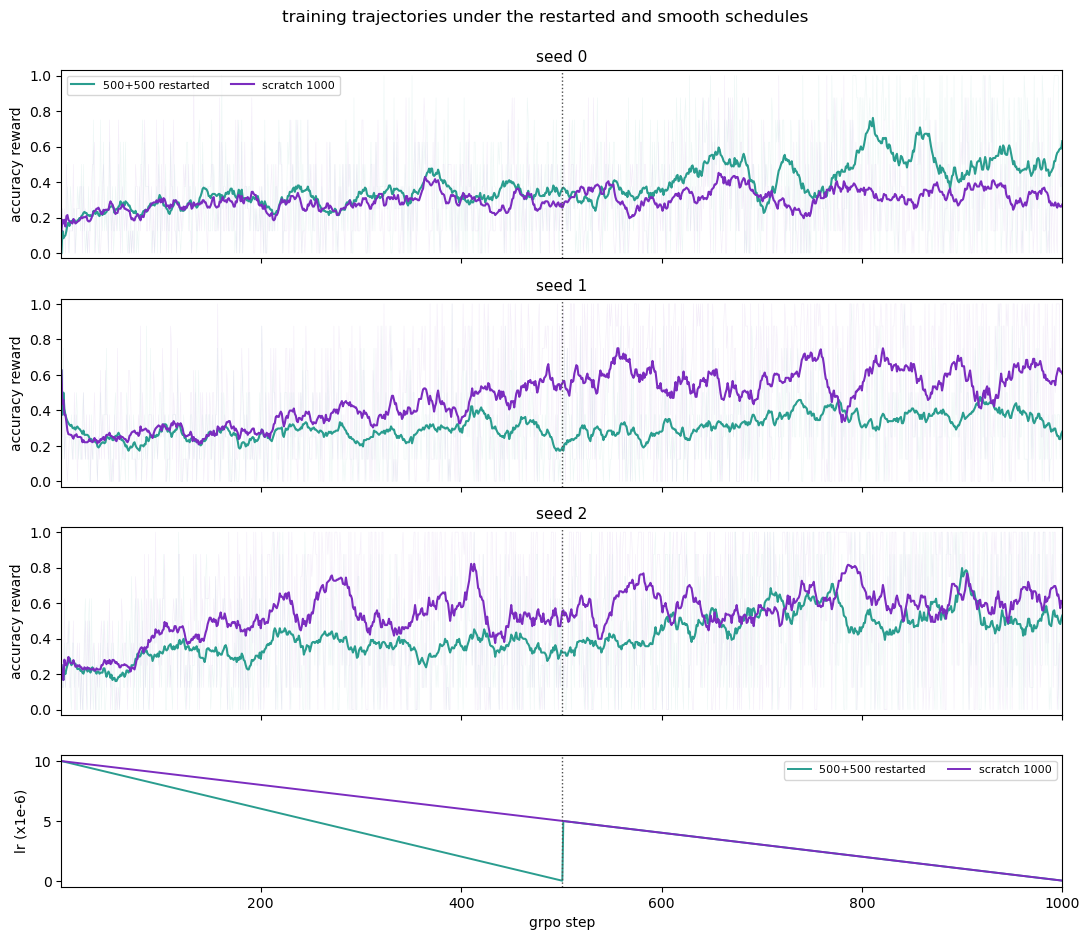

In [2]:
# compare reward and learning-rate paths for the two complete regimes
def rolling(values, window=21):
    return [sum(values[max(0, i-window+1):i+1]) / len(values[max(0, i-window+1):i+1])
            for i in range(len(values))]

def sequence(raw):
    steps = sorted(int(s) for s in raw)
    assert steps == list(range(1, 1001))
    return [raw[str(s)] for s in steps]

def learning_rates(log):
    rows = {int(e['step']): float(e['learning_rate'])
            for e in log if 'step' in e and 'learning_rate' in e}
    assert sorted(rows) == list(range(1, 1001))
    return [rows[s] for s in range(1, 1001)]

steps = np.arange(1, 1001)
fig, axes = plt.subplots(4, 1, figsize=(11, 9.4), sharex=True,
                         gridspec_kw={'height_ratios': [1, 1, 1, 0.7]})
for ax, seed in zip(axes[:3], (0, 1, 2)):
    restarted = sequence(data[seed]['restarted_curve'])
    scratch = sequence(data[seed]['scratch_curve'])
    ax.plot(steps, restarted, color=regime_colours['restarted'], lw=0.45, alpha=0.08)
    ax.plot(steps, scratch, color=regime_colours['scratch'], lw=0.45, alpha=0.08)
    ax.plot(steps, rolling(restarted), color=regime_colours['restarted'], lw=1.5, label='500+500 restarted')
    ax.plot(steps, rolling(scratch), color=regime_colours['scratch'], lw=1.5, label='scratch 1000')
    ax.axvline(500.5, color='0.3', ls=':', lw=1)
    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel('accuracy reward')
    ax.set_title(f'seed {seed}', fontsize=11)
axes[0].legend(loc='upper left', fontsize=8, ncol=2)

lr_restarted = learning_rates(data[0]['restarted_trainlog'])
lr_scratch = learning_rates(data[0]['scratch_trainlog'])
axes[3].plot(steps, np.array(lr_restarted) * 1e6, color=regime_colours['restarted'], lw=1.4,
             label='500+500 restarted')
axes[3].plot(steps, np.array(lr_scratch) * 1e6, color=regime_colours['scratch'], lw=1.4,
             label='scratch 1000')
axes[3].axvline(500.5, color='0.3', ls=':', lw=1)
axes[3].set_ylabel('lr (x1e-6)')
axes[3].set_xlabel('grpo step')
axes[3].set_xlim(1, 1000)
axes[3].legend(loc='upper right', fontsize=8, ncol=2)
fig.suptitle('training trajectories under the restarted and smooth schedules', y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_training_regimes.png'), dpi=200, bbox_inches='tight')
plt.show()


## Accuracy endpoints and seed spread


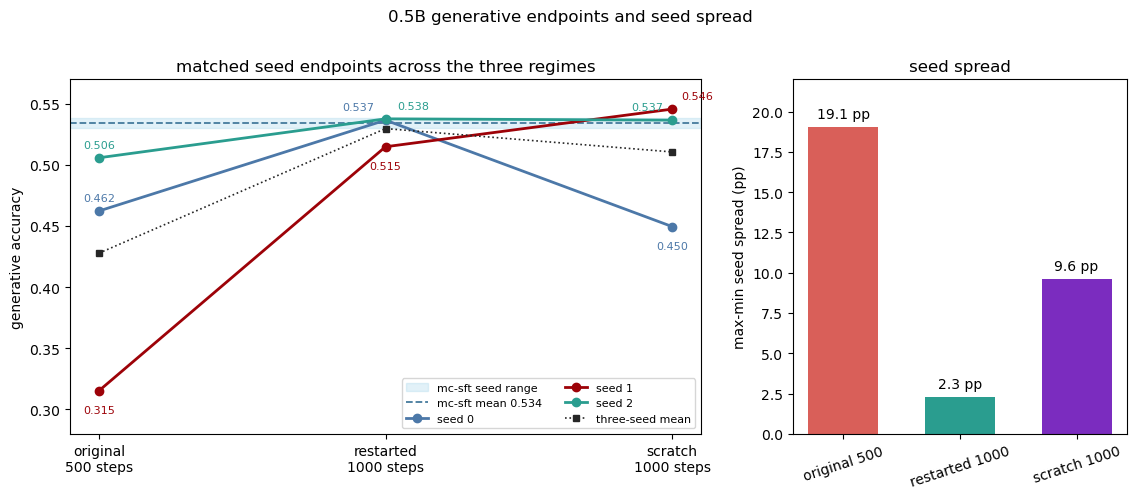

In [3]:
# compare matched seed endpoints across all three training regimes
regime_names = ['original 500', 'restarted 1000', 'scratch 1000']
values = {
    seed: [data[seed]['original_acc'], data[seed]['restarted_acc'], data[seed]['scratch_acc']]
    for seed in (0, 1, 2)
}
spreads = [(max(values[s][i] for s in values) - min(values[s][i] for s in values)) * 100
           for i in range(3)]
means = [sum(values[s][i] for s in values) / 3 for i in range(3)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.9), gridspec_kw={'width_ratios': [1.7, 0.9]})
ax1.axhspan(min(mcsft_scores), max(mcsft_scores), color='#8ecae6', alpha=0.25, label='mc-sft seed range')
ax1.axhline(mcsft_mean, color='#457b9d', ls='--', lw=1.3, label=f'mc-sft mean {mcsft_mean:.3f}')
offsets = {
    (0, 0): (0, 7), (0, 1): (-20, 7), (0, 2): (0, -16),
    (1, 0): (0, -16), (1, 1): (0, -16), (1, 2): (18, 7),
    (2, 0): (0, 7), (2, 1): (20, 7), (2, 2): (-18, 7),
}
for seed in (0, 1, 2):
    ax1.plot(range(3), values[seed], color=seed_colours[seed], lw=2, marker='o', label=f'seed {seed}')
    for i, value in enumerate(values[seed]):
        ax1.annotate(f'{value:.3f}', (i, value), xytext=offsets[(seed, i)], textcoords='offset points',
                     ha='center', fontsize=8, color=seed_colours[seed])
ax1.plot(range(3), means, color='0.15', lw=1.2, ls=':', marker='s', ms=4, label='three-seed mean')
ax1.set_xticks(range(3))
ax1.set_xticklabels(['original\n500 steps', 'restarted\n1000 steps', 'scratch\n1000 steps'])
ax1.set_ylabel('generative accuracy')
ax1.set_ylim(0.28, 0.57)
ax1.set_title('matched seed endpoints across the three regimes')
ax1.legend(fontsize=8, loc='lower right', ncol=2)

bars = ax2.bar(regime_names, spreads, color=['#d95f59', '#2a9d8f', '#7b2cbf'], width=0.6)
ax2.bar_label(bars, labels=[f'{v:.1f} pp' for v in spreads], padding=4, fontsize=10)
ax2.set_ylabel('max-min seed spread (pp)')
ax2.set_ylim(0, 22)
ax2.set_title('seed spread')
ax2.tick_params(axis='x', rotation=18)
fig.suptitle('0.5B generative endpoints and seed spread', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_endpoints_and_spread.png'), dpi=200, bbox_inches='tight')
plt.show()


## Paired generative and probe effects


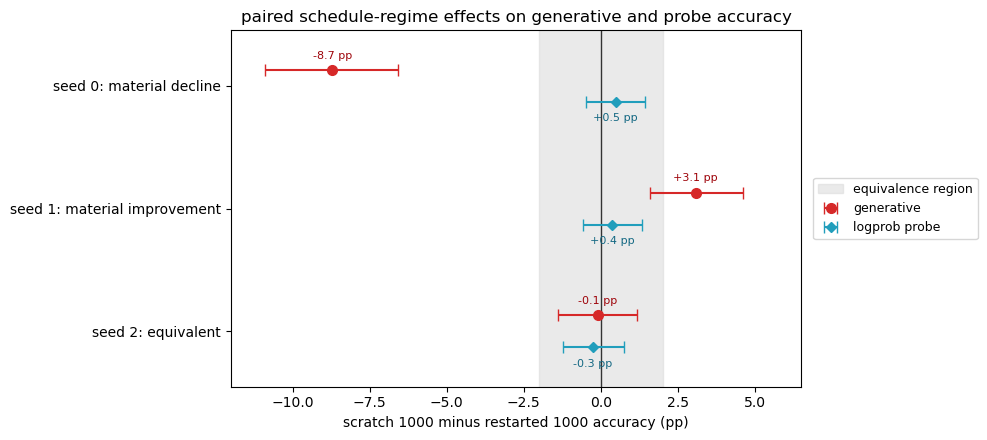

In [4]:
# plot paired schedule-regime effects with confidence intervals
seeds = [0, 1, 2]
y = np.array([2, 1, 0], dtype=float)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-2, 2, color='0.85', alpha=0.55, label='equivalence region')
ax.axvline(0, color='0.2', lw=1)
for row, seed in enumerate(seeds):
    st = stats[seed]
    gd = st['delta_vs_recovered'] * 100
    glo, ghi = np.array(st['ci']) * 100
    pd = st['probe_delta'] * 100
    plo, phi = np.array(st['probe_ci']) * 100
    yy = y[row]
    ax.errorbar(gd, yy + 0.13, xerr=[[gd - glo], [ghi - gd]], fmt='o', ms=7, capsize=4,
                color='#d62828', label='generative' if row == 0 else None)
    ax.errorbar(pd, yy - 0.13, xerr=[[pd - plo], [phi - pd]], fmt='D', ms=5, capsize=4,
                color='#219ebc', label='logprob probe' if row == 0 else None)
    ax.annotate(f'{gd:+.1f} pp', (gd, yy + 0.13), xytext=(0, 8), textcoords='offset points',
                ha='center', fontsize=8, color='#9d0208')
    ax.annotate(f'{pd:+.1f} pp', (pd, yy - 0.13), xytext=(0, -14), textcoords='offset points',
                ha='center', fontsize=8, color='#126782')
ax.set_yticks(y)
ax.set_yticklabels([f'seed {s}: {stats[s]["category"]}' for s in seeds])
ax.set_xlabel('scratch 1000 minus restarted 1000 accuracy (pp)')
ax.set_xlim(-12, 6.5)
ax.set_ylim(-0.45, 2.45)
ax.set_title('paired schedule-regime effects on generative and probe accuracy')
ax.legend(fontsize=9, loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_paired_effects.png'), dpi=200, bbox_inches='tight')
plt.show()


## Accuracy difference by tier


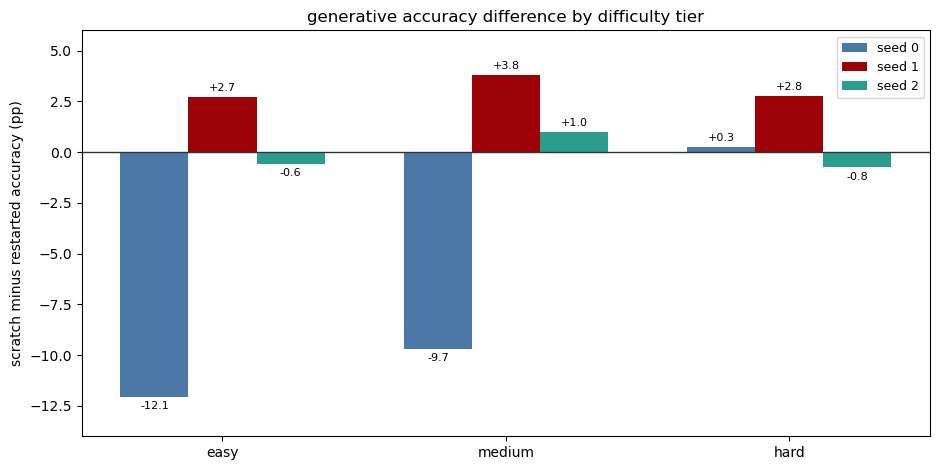

In [5]:
# compare scratch and restarted accuracy on each difficulty tier
tier_changes = {
    seed: [(stats[seed]['tiers_scratch_vs_recovered'][tier][0]
            - stats[seed]['tiers_scratch_vs_recovered'][tier][1]) * 100 for tier in TIERS]
    for seed in seeds
}
x = np.arange(len(TIERS))
width = 0.24
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for offset, seed in zip((-width, 0, width), seeds):
    bars = ax.bar(x + offset, tier_changes[seed], width, color=seed_colours[seed], label=f'seed {seed}')
    ax.bar_label(bars, labels=[f'{v:+.1f}' for v in tier_changes[seed]], padding=3, fontsize=8)
ax.axhline(0, color='0.2', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(TIERS)
ax.set_ylabel('scratch minus restarted accuracy (pp)')
ax.set_ylim(-14, 6)
ax.set_title('generative accuracy difference by difficulty tier')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_tier_differences.png'), dpi=200, bbox_inches='tight')
plt.show()


## Paired answer changes


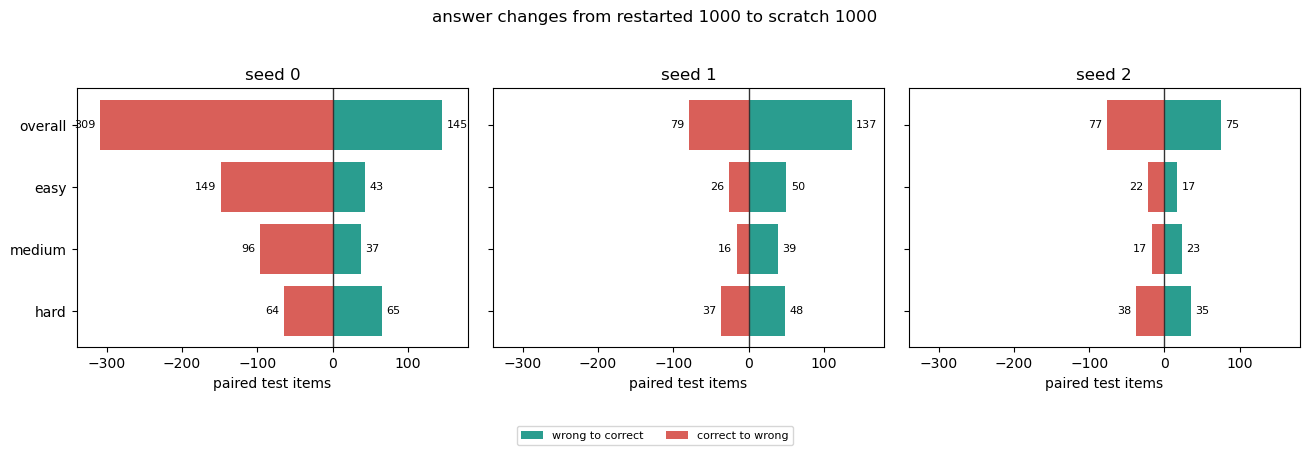

In [6]:
# count wrong-to-correct and correct-to-wrong changes from restarted to scratch
def transition_counts(old, new):
    groups = ['overall'] + list(TIERS)
    gained, lost = [], []
    for group in groups:
        pairs = [(a, b) for a, b in zip(old, new)
                 if group == 'overall' or tier_of(a['subject']) == group]
        gained.append(sum((not a['correct']) and b['correct'] for a, b in pairs))
        lost.append(sum(a['correct'] and (not b['correct']) for a, b in pairs))
    return groups, gained, lost

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.5), sharex=True, sharey=True)
for ax, seed in zip(axes, seeds):
    groups, gained, lost = transition_counts(data[seed]['restarted'], data[seed]['scratch'])
    yy = np.arange(len(groups))
    ax.barh(yy, gained, color='#2a9d8f', label='wrong to correct' if seed == 0 else None)
    ax.barh(yy, [-v for v in lost], color='#d95f59', label='correct to wrong' if seed == 0 else None)
    for row, (up, down) in enumerate(zip(gained, lost)):
        ax.text(up + 6, row, str(up), va='center', fontsize=8)
        ax.text(-down - 6, row, str(down), va='center', ha='right', fontsize=8)
    ax.axvline(0, color='0.2', lw=1)
    ax.set_yticks(yy)
    ax.set_yticklabels(groups)
    ax.set_title(f'seed {seed}')
    ax.set_xlabel('paired test items')
    ax.set_xlim(-340, 180)
axes[0].invert_yaxis()
fig.legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2)
fig.suptitle('answer changes from restarted 1000 to scratch 1000', y=0.99)
fig.tight_layout(rect=[0, 0.11, 1, 0.96])
fig.savefig(os.path.join(FIGDIR, 'fig_paired_transitions.png'), dpi=200, bbox_inches='tight')
plt.show()


## Accuracy difference by subject


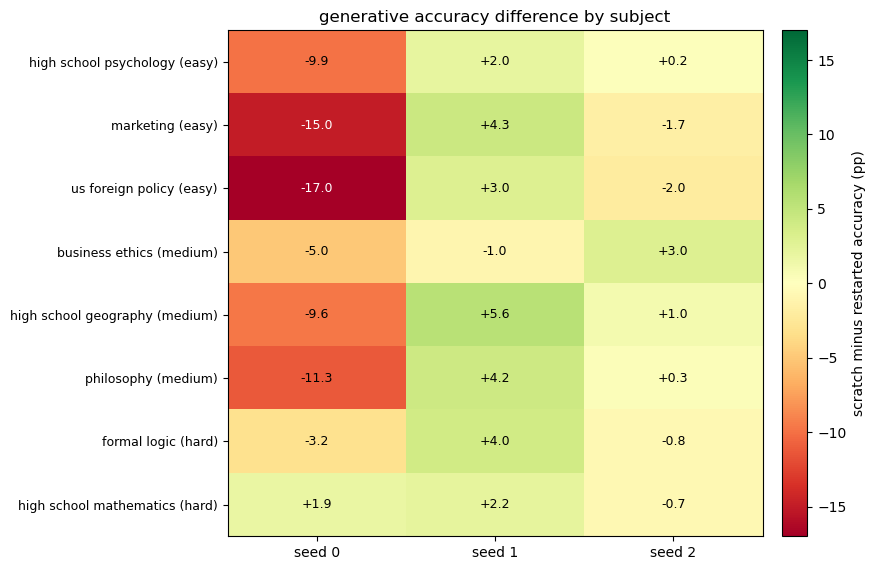

In [7]:
# compare subject-level accuracy between scratch and restarted endpoints
subjects = sorted({r['subject'] for r in data[0]['scratch']},
                  key=lambda s: (list(TIERS).index(tier_of(s)), s))
matrix = []
for subject in subjects:
    row = []
    for seed in seeds:
        restarted = [r['correct'] for r in data[seed]['restarted'] if r['subject'] == subject]
        scratch = [r['correct'] for r in data[seed]['scratch'] if r['subject'] == subject]
        row.append((sum(scratch) / len(scratch) - sum(restarted) / len(restarted)) * 100)
    matrix.append(row)
matrix = np.array(matrix)
limit = max(5, np.ceil(np.abs(matrix).max()))

fig, ax = plt.subplots(figsize=(9, 5.8))
im = ax.imshow(matrix, cmap='RdYlGn', norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
               aspect='auto', interpolation='nearest')
ax.set_xticks(np.arange(3))
ax.set_xticklabels([f'seed {s}' for s in seeds])
ax.set_yticks(np.arange(len(subjects)))
ax.set_yticklabels([f'{s.replace("_", " ")} ({tier_of(s)})' for s in subjects], fontsize=9)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        colour = heatmap_text_color(im, matrix[i, j])
        ax.text(j, i, f'{matrix[i, j]:+.1f}', ha='center', va='center', fontsize=9, color=colour)
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label('scratch minus restarted accuracy (pp)')
ax.set_title('generative accuracy difference by subject')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_subject_differences.png'), dpi=200, bbox_inches='tight')
plt.show()


## Output diagnostics


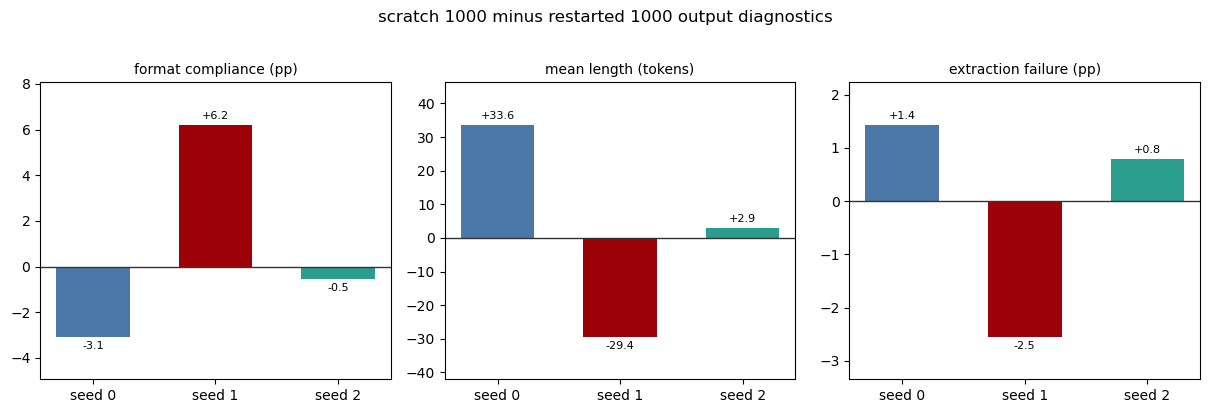

In [8]:
# compare generated-output diagnostics between the two regimes
diagnostics = {
    'format compliance (pp)': [
        (data[s]['scratch_eval']['format_compliance'] - data[s]['restarted_eval']['format_compliance']) * 100
        for s in seeds
    ],
    'mean length (tokens)': [
        data[s]['scratch_eval']['mean_len'] - data[s]['restarted_eval']['mean_len'] for s in seeds
    ],
    'extraction failure (pp)': [
        (data[s]['scratch_eval']['extraction_failure_rate']
         - data[s]['restarted_eval']['extraction_failure_rate']) * 100 for s in seeds
    ],
}
fig, axes = plt.subplots(1, 3, figsize=(12.2, 4))
for ax, (name, vals) in zip(axes, diagnostics.items()):
    bars = ax.bar([f'seed {s}' for s in seeds], vals, color=[seed_colours[s] for s in seeds], width=0.6)
    ax.axhline(0, color='0.2', lw=1)
    ax.bar_label(bars, labels=[f'{v:+.1f}' for v in vals], padding=3, fontsize=8)
    ax.set_title(name, fontsize=10)
    ax.margins(y=0.2)
fig.suptitle('scratch 1000 minus restarted 1000 output diagnostics', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_output_diagnostics.png'), dpi=200, bbox_inches='tight')
plt.show()


## Cross-referenced conclusion

The fresh 1000-step schedule did not reproduce one common outcome across the
three seeds. Compared with the matched restarted endpoints, seed 0 declined by
8.7 pp, seed 1 improved by 3.1 pp, and seed 2 was equivalent at -0.1 pp. These
are the registered Holm-gated categories, so the final result is mixed rather
than evidence for one generally better schedule.

The seed spread was 19.1 pp after the original 500 steps, 2.3 pp after the
restarted runs, and 9.6 pp after the fresh 1000-step runs. The fresh endpoints
were less variable than the original endpoints but did not match the stability
of the restarted endpoints. Their mean was 51.1%, compared with 53.0% for the
restarted runs and 53.4% for MC-SFT.

Probe differences were equivalent for every seed even though generative effects
were very different. Seed 0 also became longer, less format-compliant and more
likely to fail answer extraction, while seed 1 moved in the opposite direction.
This suggests that much of the regime difference concerns generated-answer
behaviour rather than option preference measured by the probe.

The comparison remains exploratory and specific to the 0.5B setting. The two
regimes differ in learning-rate shape and cumulative exposure, so this does not
isolate the causal effect of resetting the learning rate.
